# Exámen 1:

### Integrantes:
- Alejandro Vásquez Sánchez ID:1000317668
- Alejandro Gutiérrez Muñoz ID: 1000317609
- Santiago Vera Ramírez ID: 1000304910


## Ejercicio 1 — Análisis de Riesgo de la Acción de Universal Health Services (UHS)

Se analizan los rendimientos diarios de UHS entre el 1 de enero de 2023 y el 20 de febrero de 2025.  
El rendimiento diario se define como:

$$r_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1$$

Se abordan los siguientes puntos:
1. Estimación de la EDF de los rendimientos.
2. Banda de confianza no paramétrica al 95% (DKW).
3. Cotas para la probabilidad de pérdida máxima del 5%.
4. Estimadores Plug-in de la asimetría y la media, con IC al 95% para la media.
5. Evaluación de la viabilidad de inversión en UHS.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt

In [ ]:
data = pd.read_csv('Universal Health Services Stock Price History.csv')

data['Date'] = pd.to_datetime(data['Date'])
data = data.sort_values(by='Date')

prices = data['Price'].values
returns = (prices[1:] - prices[:-1]) / prices[:-1]

n = len(returns)
print(f"Número de precios:    {len(prices)}")
print(f"Número de retornos:   {n}  (= precios - 1)")
print(f"Rango de retornos:    [{returns.min():.4f}, {returns.max():.4f}]")
print(f"¿Algún NaN?:          {np.isnan(returns).any()}")

Número de precios:    535
Número de retornos:   534  (= precios - 1)
Rango de retornos:    [-0.0975, 0.1023]
¿Algún NaN?:          False


### Ítem 1 — Función de Distribución Empírica (EDF)

La EDF asigna masa de probabilidad $1/n$ a cada dato observado. Para cualquier valor $x$:

$$\hat{F}_n(x) = \frac{1}{n} \sum_{i=1}^{n} \mathbf{1}(X_i \leq x)$$

No se asume ninguna distribución teórica: es un estimador puramente no paramétrico.

In [ ]:
def empirical_cdf(x, sample):
    """Calcula el valor de la EDF en el punto x para una muestra dada."""
    return np.mean(sample <= x)

In [ ]:

x_grid = np.linspace(returns.min(), returns.max(), 200)

# Para cada punto de la malla, se cuenta la proporción de retornos <= x
edf_values = np.array([empirical_cdf(x, returns) for x in x_grid])

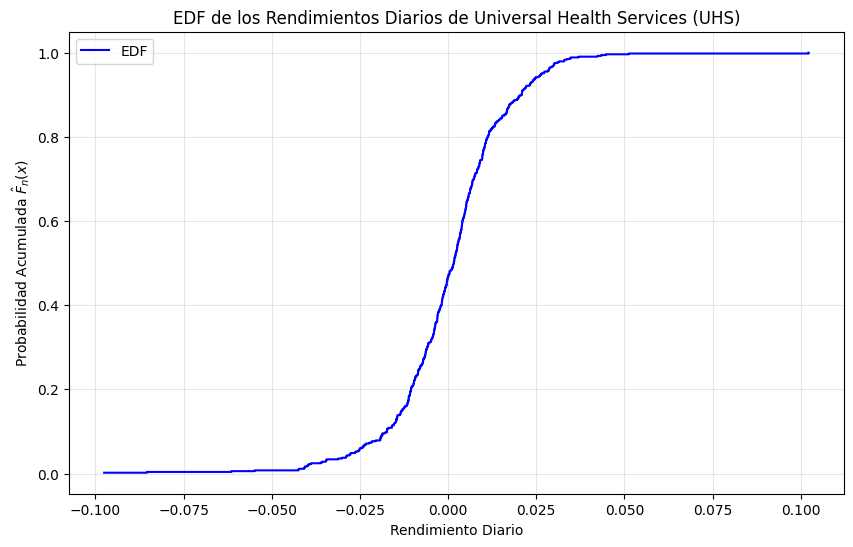

In [ ]:
# sorted_returns: retornos ordenados de menor a mayor → eje x de los escalones
# y_edf: para el i-ésimo retorno ordenado, acumula i/n de probabilidad
sorted_returns = np.sort(returns)
y_edf = np.arange(1, n + 1) / n

plt.figure(figsize=(10, 6))
plt.step(sorted_returns, y_edf, where='post', label='EDF', color='blue')
plt.title('EDF de los Rendimientos Diarios de Universal Health Services (UHS)')
plt.xlabel('Rendimiento Diario')
plt.ylabel('Probabilidad Acumulada $\\hat{F}_n(x)$')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


La EDF muestra que la mayor parte de los rendimientos diarios de UHS se concentra cerca de cero, ya que la curva crece con rapidez alrededor de valores pequeños. Esto indica que, en general, los cambios diarios más frecuentes fueron moderados y no extremos.


### Ítem 2 — Banda de Confianza No Paramétrica al 95% (DKW)

A partir de la desigualdad de Dvoretzky-Kiefer-Wolfowitz (DKW), se construye una banda de
confianza de nivel $1 - \alpha$ para la CDF verdadera $F(x)$:

$$\epsilon_n = \sqrt{\frac{1}{2n} \log\left(\frac{2}{\alpha}\right)}$$

$$L(x) = \max\{\hat{F}_n(x) - \epsilon_n,\ 0\}, \quad U(x) = \min\{\hat{F}_n(x) + \epsilon_n,\ 1\}$$

Con probabilidad $\geq 1 - \alpha$, la CDF verdadera queda contenida en la banda $[L(x), U(x)]$
para todo $x$ simultáneamente. Este resultado no depende de ningún supuesto sobre $F$.

In [ ]:
# Calcular epsilon_n con alpha = 0.05
alpha = 0.05
epsilon_n = np.sqrt(np.log(2 / alpha) / (2 * n))
print(f"n = {n},  epsilon_n = {epsilon_n:.4f}")


L_values = np.maximum(edf_values - epsilon_n, 0)
U_values = np.minimum(edf_values + epsilon_n, 1)

n = 534,  epsilon_n = 0.0588


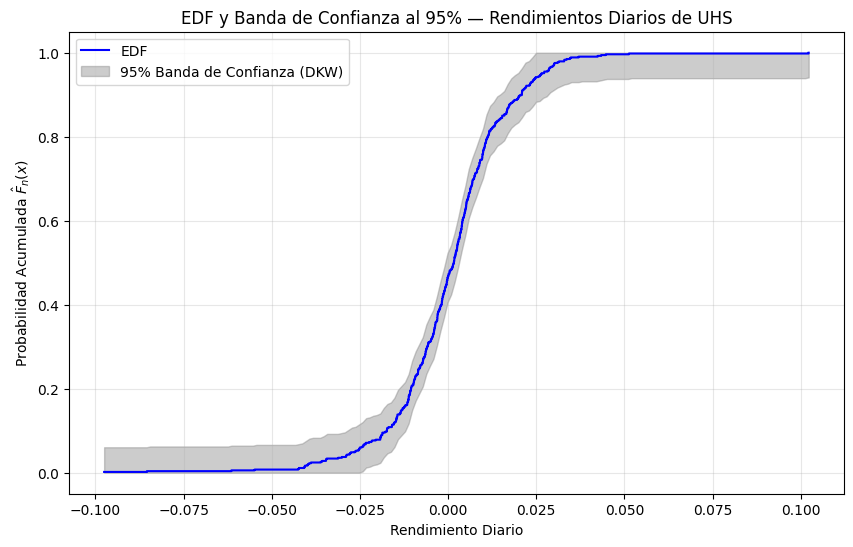

In [ ]:
plt.figure(figsize=(10, 6))

# EDF escalonada sobre los datos reales (sorted_returns + y_edf)
plt.step(sorted_returns, y_edf, where='post', label='EDF', color='blue')

# Banda de confianza sobre la malla uniforme
plt.fill_between(x_grid, L_values, U_values, color='gray',
                 alpha=0.4, label='95% Banda de Confianza (DKW)')

plt.title('EDF y Banda de Confianza al 95% — Rendimientos Diarios de UHS')
plt.xlabel('Rendimiento Diario')
plt.ylabel('Probabilidad Acumulada $\\hat{F}_n(x)$')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

La banda de confianza complementa la EDF al mostrar la incertidumbre de la estimación. En este caso, la banda permanece relativamente cercana a la curva empírica, lo que sugiere que la muestra describe razonablemente bien la distribución de los rendimientos.

- En la zona central, donde hay más observaciones, la estimación es más estable.
- En las colas, la interpretación debe hacerse con más cuidado, porque hay menos datos (eventos poco frecuentes), lo cual hace que allí también aumente un poco más la incentidumbre.

### Ítem 3 — Cotas para la Probabilidad de Pérdida Máxima del 5%

Una pérdida del 5% corresponde a un rendimiento $r_t \leq -0.05$.  
La probabilidad empírica de ese evento es $\hat{F}_n(-0.05)$.

Usando la banda DKW evaluada en $x = -0.05$:

$$[L(-0.05),\ U(-0.05)]$$

se obtiene una **cota inferior** y una **cota superior** para $P(r_t \leq -0.05)$ con al menos 95% de confianza.

In [ ]:
threshold = -0.05

edf_at_threshold = empirical_cdf(threshold, returns)
L_at_threshold   = max(edf_at_threshold - epsilon_n, 0)
U_at_threshold   = min(edf_at_threshold + epsilon_n, 1)

print(f"Estimación puntual  F_n(-0.05) = {edf_at_threshold:.4f}  ({edf_at_threshold*100:.2f}%)")
print(f"Cota inferior       L(-0.05)   = {L_at_threshold:.4f}  ({L_at_threshold*100:.2f}%)")
print(f"Cota superior       U(-0.05)   = {U_at_threshold:.4f}  ({U_at_threshold*100:.2f}%)")

Estimación puntual  F_n(-0.05) = 0.0075  (0.75%)
Cota inferior       L(-0.05)   = 0.0000  (0.00%)
Cota superior       U(-0.05)   = 0.0663  (6.63%)


#### 3. Interpretación de la probabilidad de pérdida diaria mayor al 5%

La estimación puntual de la probabilidad de una pérdida diaria de al menos 5% es baja (0.75%), lo que indica que este tipo de evento fue poco frecuente en la muestra. Sin embargo, la banda de confianza muestra que esa probabilidad aún podría ser mayor.

- La cota inferior igual a 0% sugiere que, con la información disponible, el evento es muy poco probable.
- La cota superior de 6.63% muestra que todavía existe incertidumbre sobre la magnitud real de ese riesgo y que dicha probabilidad puede llegar a ser mayor.

### Ítem 4 — Estimadores Plug-in: Asimetría y Media; IC al 95% para la Media

El **principio plug-in** consiste en reemplazar la CDF desconocida $F$ por la EDF $\hat{F}_n$
dentro del funcional de interés $T(F)$:

$$\hat{\theta}_n = T(\hat{F}_n)$$

Como $\hat{F}_n$ asigna masa $1/n$ a cada dato, las integrales se convierten en promedios muestrales:

- **Media plug-in:** $\hat{\mu}_n = \frac{1}{n}\sum X_i = \bar{X}_n$
- **Varianza plug-in (sesgada):** $\hat{\sigma}^2_n = \frac{1}{n}\sum (X_i - \bar{X}_n)^2$
- **Asimetría plug-in:** $\hat{\kappa}_n = \dfrac{\frac{1}{n}\sum (X_i - \bar{X}_n)^3}{(\hat{\sigma}^2_n)^{3/2}}$
- **IC al 95% para la media:** $\bar{X}_n \pm 1.96 \cdot \dfrac{\hat{\sigma}_n}{\sqrt{n}}$

**Aclaración:** para el intervalo de confianza de la media, usaremos la la varianza muestral insesgada, tal como plantea el material de clase. Este estimador también se reporta a continuación:

- **Varianza muestral (insesgada):** $\hat{\sigma}^2_n = \frac{1}{n-1}\sum (X_i - \bar{X}_n)^2$

In [ ]:
def plugin_mean(sample):
    return np.mean(sample)

def plugin_variance_insesgada(sample):
    n = len(sample)
    mu = np.mean(sample)
    var_sesgada = np.mean((sample - mu)**2)
    return n/(n-1)*var_sesgada

def plugin_variance_sesgada(sample):
    mu = np.mean(sample)
    return np.mean((sample - mu)**2)

def plugin_skewness(sample):
    mu    = plugin_mean(sample)
    var   = plugin_variance_sesgada(sample)
    if var == 0:
        return 0
    sigma = sqrt(var)
    return np.mean((sample - mu)**3) / (sigma**3)

In [ ]:
# Estimaciones puntuales
mu_hat   = plugin_mean(returns)
var_hat_ses  = plugin_variance_sesgada(returns)
var_hat_inses = plugin_variance_insesgada(returns)
skew_hat = plugin_skewness(returns)

print(f"Media plug-in:      {mu_hat:.6f}  ({mu_hat*100:.4f}% diario)")
print(f"Varianza plug-in (sesgada):   {var_hat_ses:.8f}")
print(f"Varianza muestral (insesgada):   {var_hat_inses:.8f}")
print(f"Asimetría plug-in:  {skew_hat:.4f}")

# Intervalo de confianza al 95% para la media (basado en la normal, z_{0.975} = 1.96)
sigma_hat = sqrt(var_hat_inses)
se_hat    = sigma_hat / sqrt(n)
z         = 1.96

ci_lower = mu_hat - z * se_hat
ci_upper = mu_hat + z * se_hat

print(f"\nIC 95% para la media: [{ci_lower:.6f}, {ci_upper:.6f}]")
print(f"El intervalo {'SÍ ' if ci_lower <= 0 <= ci_upper else ''}contiene el cero.")

Media plug-in:      0.000622  (0.0622% diario)
Varianza plug-in (sesgada):   0.00028464
Varianza plug-in (insesgada):   0.00028518
Asimetría plug-in:  -0.3905

IC 95% para la media: [-0.000810, 0.002054]
El intervalo SÍ contiene el cero.


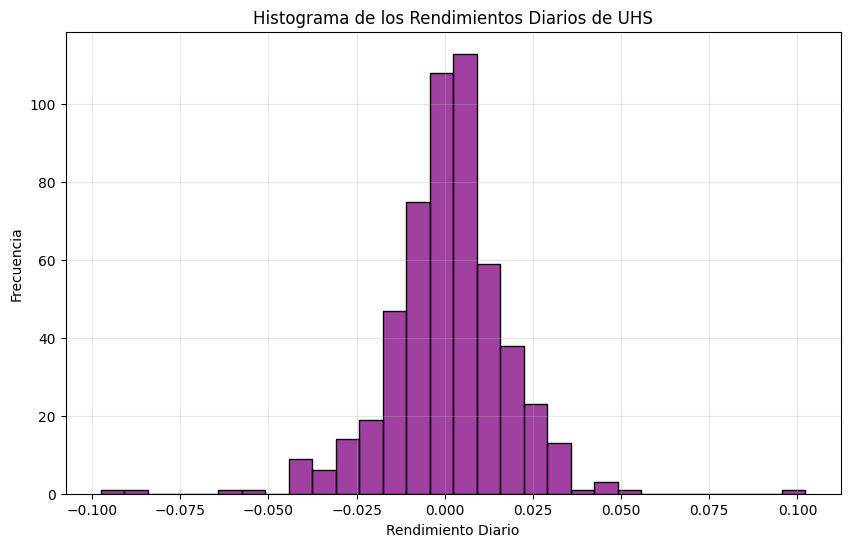

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(returns, bins=30, color='purple')
plt.title('Histograma de los Rendimientos Diarios de UHS')
plt.xlabel('Rendimiento Diario')
plt.ylabel('Frecuencia')
plt.grid(alpha=0.3)
plt.show()

La media plug-in estimada es positiva, pero muy pequeña, por lo que sugiere un rendimiento promedio diario levemente favorable. No obstante, el intervalo de confianza para la media incluye el cero, así que no hay evidencia estadística suficiente para afirmar que el rendimiento promedio sea realmente distinto de cero.

Además, la asimetría negativa indica una cola izquierda más pesada, es decir, una mayor presencia relativa de pérdidas extremas frente a ganancias extremas comparables. Esto también se observa en el histograma, donde la mayor parte de los datos se concentra cerca de cero, pero con cierta descompensación hacia el lado negativo. Introduce una señal importante de riesgo.


### Ítem 5 — Evaluación de la Viabilidad de Inversión en UHS

#### 5. Evaluación final sobre la viabilidad de invertir en UHS

Los resultados sugieren que UHS no presenta, en general, una dinámica diaria extremadamente volátil, ya que la mayor parte de sus rendimientos se concentra cerca de cero y la probabilidad estimada de pérdidas diarias superiores al 5% es baja. Sin embargo, la evaluación no debe basarse únicamente en el rendimiento promedio, porque aunque la media estimada es positiva, su intervalo de confianza incluye el cero, y la asimetría negativa indica exposición a eventos adversos en la cola izquierda.

Por tanto, estos cálculos constituyen un buen punto de partida para describir la distribución de los rendimientos y obtener una primera aproximación al riesgo, pero no son suficientes por sí solos para tomar una decisión de inversión completa.

Para fortalecer el análisis, sería recomendable incorporar un estudio temporal más clara, por ejemplo, estudiando si la media, la volatilidad y la forma de la distribución cambian a lo largo del tiempo, hacer pronósticos con los datos disponibles o mediante ventanas móviles que permitan identificar tendencias temporales, cambios de régimen o episodios de mayor inestabilidad que complementen la toma de decisiones.

También sería útil incluir variables exógenas que puedan influir en el comportamiento de la acción, como el desempeño del mercado general, índices del sector salud, tasas de interés, inflación, anuncios de resultados financieros, cambios regulatorios o eventos macroeconómicos relevantes. Finalmente, la decisión podría complementarse con comparaciones frente a activos de referencia y con métricas financieras de riesgo y desempeño, como Sharpe, Sortino, VaR, Expected Shortfall o drawdown, para obtener una visión más completa de la conveniencia de invertir en la empresa.


## Ejercicio 2: Relación entre peso y consumo de combustible en `mtcars`

En este ejercicio vamos a explorar la relación entre el peso de un vehículo (`wt`) y su eficiencia en combustible (`mpg`) usando el dataset `mtcars`. La idea es analizar la correlación entre estas dos variables y ver cómo los valores atípicos pueden afectar esa relación.

### 0. Importación de librerías y carga de datos

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2
from numpy.linalg import inv
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN


mtcars = pd.read_csv("mtcars.csv")

print("Dimensiones del dataset:", mtcars.shape)
mtcars

Dimensiones del dataset: (32, 12)


,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2
5,Valiant,18.1,6,225.0,105,2.76,3.460,20.22,1,0,3,1
6,Duster 360,14.3,8,360.0,245,3.21,3.570,15.84,0,0,3,4
7,Merc 240D,24.4,4,146.7,62,3.69,3.190,20.00,1,0,4,2
8,Merc 230,22.8,4,140.8,95,3.92,3.150,22.90,1,0,4,2
9,Merc 280,19.2,6,167.6,123,3.92,3.440,18.30,1,0,4,4


---
### 1. Análisis descriptivo de `mpg` y `wt`

Antes de entrar a las correlaciones o la detección de outliers, lo primero es entender cómo se comportan individualmente las dos variables de interés.

In [3]:

desc = mtcars[['mpg', 'wt']].describe()
print("Estadísticas descriptivas:")
print(desc)

Estadísticas descriptivas:
             mpg         wt
count  32.000000  32.000000
mean   20.090625   3.217250
std     6.026948   0.978457
min    10.400000   1.513000
25%    15.425000   2.581250
50%    19.200000   3.325000
75%    22.800000   3.610000
max    33.900000   5.424000


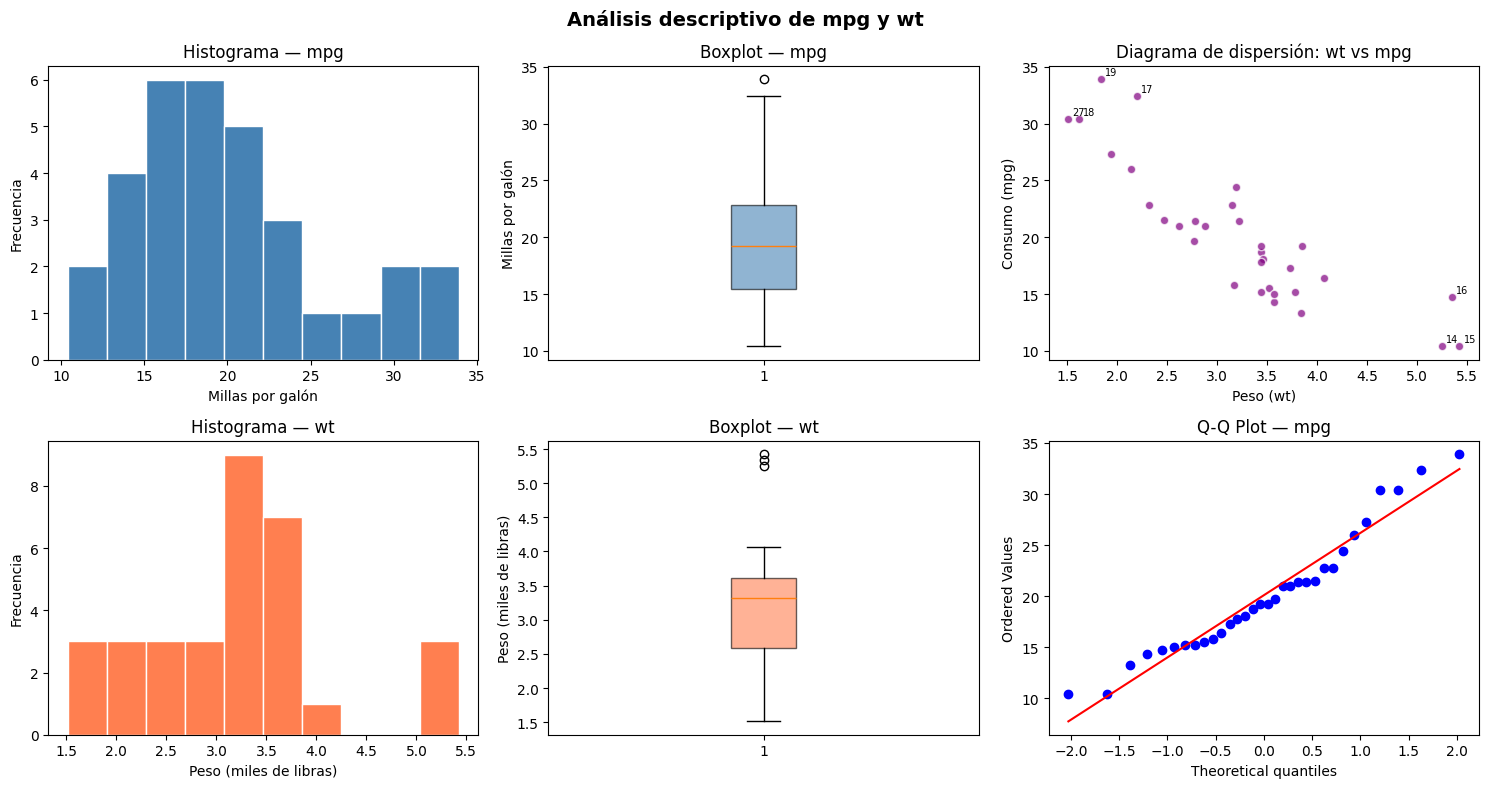

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Análisis descriptivo de mpg y wt', fontsize=14, fontweight='bold')

# Histogramas
axes[0, 0].hist(mtcars['mpg'], bins=10, color='steelblue', edgecolor='white')
axes[0, 0].set_title('Histograma — mpg')
axes[0, 0].set_xlabel('Millas por galón')
axes[0, 0].set_ylabel('Frecuencia')

axes[1, 0].hist(mtcars['wt'], bins=10, color='coral', edgecolor='white')
axes[1, 0].set_title('Histograma — wt')
axes[1, 0].set_xlabel('Peso (miles de libras)')
axes[1, 0].set_ylabel('Frecuencia')

# Boxplots
axes[0, 1].boxplot(mtcars['mpg'], patch_artist=True,
                   boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[0, 1].set_title('Boxplot — mpg')
axes[0, 1].set_ylabel('Millas por galón')

axes[1, 1].boxplot(mtcars['wt'], patch_artist=True,
                   boxprops=dict(facecolor='coral', alpha=0.6))
axes[1, 1].set_title('Boxplot — wt')
axes[1, 1].set_ylabel('Peso (miles de libras)')

# Scatter plot
axes[0, 2].scatter(mtcars['wt'], mtcars['mpg'], color='purple', alpha=0.7, edgecolors='white')
axes[0, 2].set_title('Diagrama de dispersión: wt vs mpg')
axes[0, 2].set_xlabel('Peso (wt)')
axes[0, 2].set_ylabel('Consumo (mpg)')

# Etiquetamos algunos puntos extremos
for i, row in mtcars.iterrows():
    if row['mpg'] > 30 or row['wt'] > 5:
        axes[0, 2].annotate(i, (row['wt'], row['mpg']), fontsize=7,
                            xytext=(3, 3), textcoords='offset points')

# Q-Q plots
stats.probplot(mtcars['mpg'], dist="norm", plot=axes[1, 2])
axes[1, 2].set_title('Q-Q Plot — mpg')

plt.tight_layout()
plt.show()

Del scatter plot se confirma lo que se esperaba: a mayor peso del vehículo, menor eficiencia en combustible. La relación parece bastante clara y negativa. También se nota que hay algunos puntos que podrían estar alejados del patrón general, como los autos con `mpg` muy alto (carros ligeros y eficientes) o con `wt` muy elevado. El Q-Q plot de `mpg` muestra que los extremos se desvían un poco de la normalidad, lo que ya nos da una pista de que hay valores atípicos.

---
### 2. Correlaciones: Pearson, Spearman y Kendall

Calculamos los tres coeficientes de correlación para la relación entre `mpg` y `wt`.

In [5]:
pearson_r, pearson_p   = stats.pearsonr(mtcars['mpg'], mtcars['wt'])
spearman_r, spearman_p = stats.spearmanr(mtcars['mpg'], mtcars['wt'])
kendall_r, kendall_p   = stats.kendalltau(mtcars['mpg'], mtcars['wt'])

print(f"Pearson  r = {pearson_r:.4f}   (p-valor = {pearson_p:.4f})")
print(f"Spearman r = {spearman_r:.4f}   (p-valor = {spearman_p:.4f})")
print(f"Kendall  τ = {kendall_r:.4f}   (p-valor = {kendall_p:.4f})")

Pearson  r = -0.8677   (p-valor = 0.0000)
Spearman r = -0.8864   (p-valor = 0.0000)
Kendall  τ = -0.7278   (p-valor = 0.0000)


#### Interpretación y diferencias conceptuales

Los tres coeficientes coinciden en que la relación entre `wt` y `mpg` es **negativa y fuerte**, con p-valores muy pequeños, lo que indica que la correlación es estadísticamente significativa.

Ahora bien, ¿por qué calcular los tres si todos dicen lo mismo? Porque no siempre van a dar el mismo resultado, y cada uno mide cosas distintas:

- **Pearson**: Mide la correlación lineal entre las dos variables. Asume que la relación es lineal y que los datos siguen aproximadamente una distribución normal. Su problema es que es muy sensible a los outliers: un valor extremo puede inflar o desinflar drásticamente el coeficiente.

- **Spearman**: En vez de trabajar con los valores directamente, trabaja con los rangos (posiciones ordenadas). Esto lo hace mucho más robusto ante outliers y no requiere suponer linealidad.

- **Kendall**: También basado en rangos, pero su lógica es diferente: cuenta cuántos pares de observaciones son concordantes (cuando una sube, la otra también baja, en el sentido esperado) versus discordantes. Es incluso más robusto que Spearman ante outliers y muestras pequeñas, aunque normalmente da valores más bajos en magnitud debido a la forma en que se calcula su métrica.

En este caso los tres son altos y negativos (~-0.87, ~-0.89, ~-0.74), lo que confirma que la relación negativa entre peso y eficiencia es robusta. Pero esto podría cambiar si hay outliers influyentes, lo que analizamos a continuación.

---
### 3. Detección de valores atípicos

Vamos a usar cuatro métodos: dos univariados (boxplot/IQR y mediana+MADN) y dos multivariados (distancia de Mahalanobis y DBSCAN).

#### 3.1 Método univariado 1: Boxplot / Regla del IQR

Este es el método clásico del boxplot. Un valor se considera outlier si cae fuera del rango `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [6]:
def detectar_outliers_iqr(serie, nombre):
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    outliers = serie[(serie < lim_inf) | (serie > lim_sup)]
    print(f"--- {nombre} ---")
    print(f"  Q1={Q1:.3f}, Q3={Q3:.3f}, IQR={IQR:.3f}")
    print(f"  Límite inferior: {lim_inf:.3f}  |  Límite superior: {lim_sup:.3f}")
    print(f"  Outliers detectados ({len(outliers)}): {list(outliers.index)}")
    print(f"  Valores: {list(outliers.values)}\n")
    return outliers.index.tolist()

out_iqr_mpg = detectar_outliers_iqr(mtcars['mpg'], 'mpg')
out_iqr_wt  = detectar_outliers_iqr(mtcars['wt'], 'wt')

--- mpg ---
  Q1=15.425, Q3=22.800, IQR=7.375
  Límite inferior: 4.363  |  Límite superior: 33.862
  Outliers detectados (1): [19]
  Valores: [np.float64(33.9)]

--- wt ---
  Q1=2.581, Q3=3.610, IQR=1.029
  Límite inferior: 1.038  |  Límite superior: 5.153
  Outliers detectados (3): [14, 15, 16]
  Valores: [np.float64(5.25), np.float64(5.424), np.float64(5.345)]



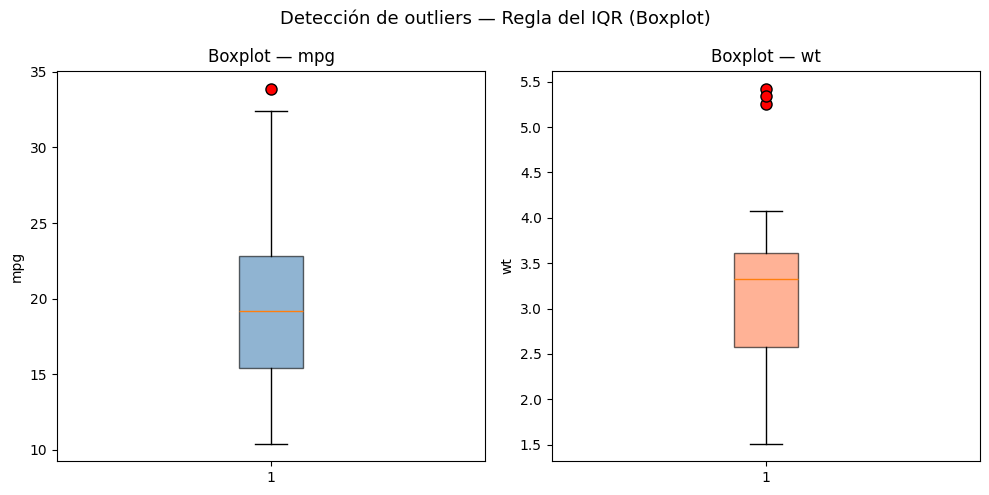

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle('Detección de outliers — Regla del IQR (Boxplot)', fontsize=13)

for ax, var, color in zip(axes, ['mpg', 'wt'], ['steelblue', 'coral']):
    ax.boxplot(mtcars[var], patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.6),
               flierprops=dict(marker='o', markerfacecolor='red', markersize=8))
    ax.set_title(f'Boxplot — {var}')
    ax.set_ylabel(var)

plt.tight_layout()
plt.show()

La regla del IQR identifica como outlier en `mpg` únicamente el auto con consumo más alto: el **Toyota Corolla** (índice 19, mpg = 33.9), que es el único que supera el límite superior de 33.862. En `wt`, en cambio, sí se detectan tres outliers: el **Cadillac Fleetwood**, **Lincoln Continental** y **Chrysler Imperial** (índices 14, 15 y 16), todos con pesos superiores al límite superior de 5.153 miles de libras. Esto tiene sentido, ya que estos son vehículos americanos muy grandes y pesados que se alejan del resto del conjunto de datos.


#### 3.2 Método univariado 2: Mediana y MADN (versión robusta)

Como la media y la desviación estándar se ven afectadas por los propios outliers que queremos detectar, usamos la versión robusta: mediana y MADN (desviación absoluta mediana normalizada). Un valor se considera outlier si `|xi - mediana| / MADN > 3`.

In [8]:
def detectar_outliers_madn(serie, nombre, umbral=3):
    mediana = np.median(serie)
    mad = np.median(np.abs(serie - mediana))
    madn = 1.4826 * mad
    t_robusto = np.abs(serie - mediana) / madn
    outliers = serie[t_robusto > umbral]
    print(f"--- {nombre} ---")
    print(f"  Mediana={mediana:.3f}, MAD={mad:.3f}, MADN={madn:.3f}")
    print(f"  Outliers detectados ({len(outliers)}): {list(outliers.index)}")
    print(f"  Valores: {list(outliers.values)}\n")
    return outliers.index.tolist()

out_madn_mpg = detectar_outliers_madn(mtcars['mpg'], 'mpg')
out_madn_wt  = detectar_outliers_madn(mtcars['wt'], 'wt')

--- mpg ---
  Mediana=19.200, MAD=3.650, MADN=5.411
  Outliers detectados (0): []
  Valores: []

--- wt ---
  Mediana=3.325, MAD=0.517, MADN=0.767
  Outliers detectados (0): []
  Valores: []



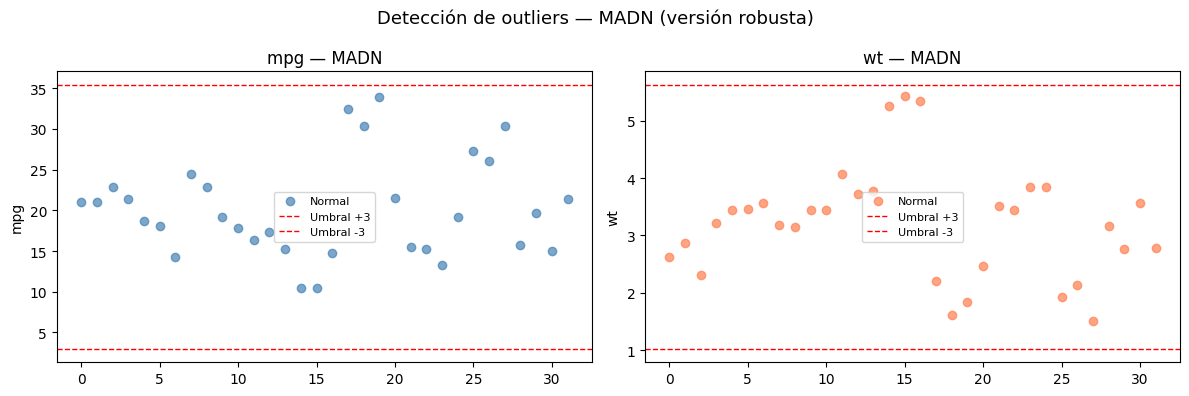

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Detección de outliers — MADN (versión robusta)', fontsize=13)

for ax, var, color, outliers in zip(
    axes,
    ['mpg', 'wt'],
    ['steelblue', 'coral'],
    [out_madn_mpg, out_madn_wt]
):
    mediana = np.median(mtcars[var])
    mad = np.median(np.abs(mtcars[var] - mediana))
    madn = 1.4826 * mad

    ax.scatter(range(len(mtcars)), mtcars[var].values, color=color, alpha=0.7, label='Normal')
    if outliers:
        idx = [mtcars.index.get_loc(o) for o in outliers]
        ax.scatter(idx, mtcars.loc[outliers, var].values,
                   color='red', zorder=5, s=80, label='Outlier')
        for i, o in zip(idx, outliers):
            ax.annotate(o, (i, mtcars.loc[o, var]), fontsize=7,
                        xytext=(3, 3), textcoords='offset points')

    ax.axhline(mediana + 3 * madn, color='red', linestyle='--', linewidth=1, label='Umbral +3')
    ax.axhline(mediana - 3 * madn, color='red', linestyle='--', linewidth=1, label='Umbral -3')
    ax.set_title(f'{var} — MADN')
    ax.set_ylabel(var)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

A diferencia del método IQR, la versión robusta con MADN **no detecta ningún outlier** ni en `mpg` ni en `wt`. Esto se debe a que el umbral de 3 MADN es más conservador: aunque el Toyota Corolla tiene el mpg más alto y los tres autos pesados se alejan bastante, ninguno supera el umbral de `|xi - mediana| / MADN > 3`. Esta discrepancia entre IQR y MADN es informativa: el IQR es más sensible a valores extremos en los extremos de la distribución, mientras que el MADN requiere que un valor esté aún más lejos de la mediana (en términos de desviación absoluta) para ser marcado. En este caso, los métodos univariados no coinciden, lo que nos indica que los posibles outliers no son tan evidentes cuando se analiza cada variable por separado.


#### 3.3 Método multivariado 1: Distancia de Mahalanobis

La distancia de Mahalanobis tiene en cuenta la correlación entre `mpg` y `wt` para detectar puntos que son atípicos en la combinación de las dos variables. Si los datos siguieran una distribución normal bivariada, entonces $D_i^2 \sim \chi^2_2$, así que usamos $\chi^2_{2, 0.95} \approx 5.99$ como umbral.

In [10]:
X = mtcars[['mpg', 'wt']].values
mean_vec = np.mean(X, axis=0).reshape(-1, 1)
cov_mat  = np.cov(X.T)
inv_cov  = inv(cov_mat)

D2 = []
for i in range(len(X)):
    x_i  = X[i].reshape(-1, 1)
    diff = x_i - mean_vec
    d2   = float(diff.T @ inv_cov @ diff)
    D2.append(d2)

mtcars_plot = mtcars.copy()
mtcars_plot['D2'] = D2

umbral_chi2 = chi2.ppf(0.95, df=2)
mtcars_plot['outlier_maha'] = mtcars_plot['D2'] > umbral_chi2

print(f"Umbral chi2(2, 0.95) = {umbral_chi2:.3f}")
print(f"Outliers detectados ({mtcars_plot['outlier_maha'].sum()}):")
print(mtcars_plot[mtcars_plot['outlier_maha']][['mpg', 'wt', 'D2']])

Umbral chi2(2, 0.95) = 5.991
Outliers detectados (3):
     mpg     wt        D2
16  14.7  5.345  8.713359
17  32.4  2.200  6.341891
19  33.9  1.835  6.589261


/tmp/ipykernel_9782/20567629.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  d2   = float(diff.T @ inv_cov @ diff)


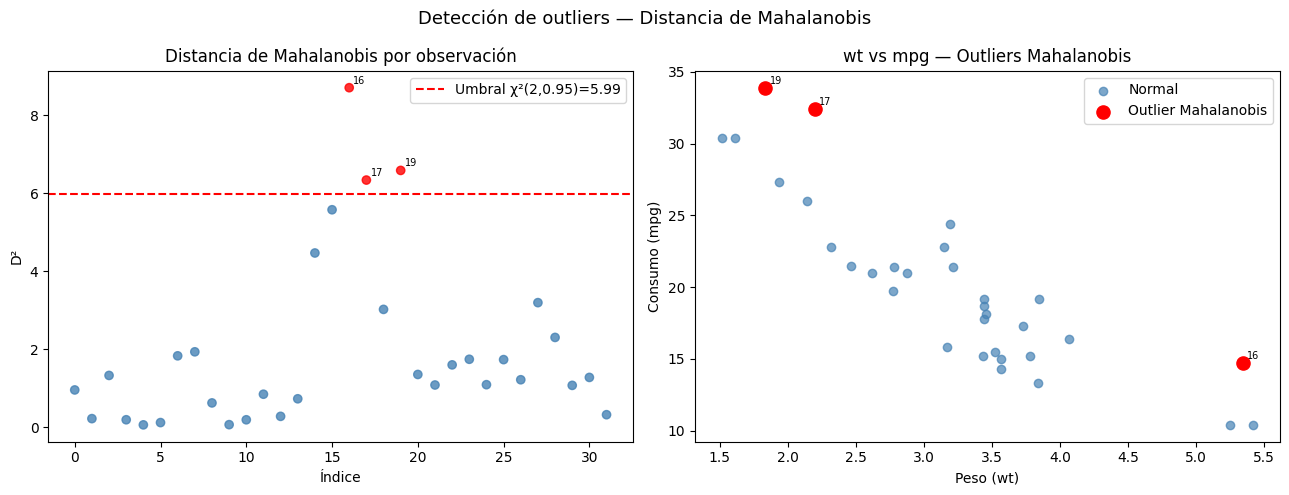

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Detección de outliers — Distancia de Mahalanobis', fontsize=13)

# Plot de distancias D2
colores = ['red' if o else 'steelblue' for o in mtcars_plot['outlier_maha']]
axes[0].scatter(range(len(mtcars_plot)), mtcars_plot['D2'], c=colores, alpha=0.8)
axes[0].axhline(umbral_chi2, color='red', linestyle='--', label=f'Umbral χ²(2,0.95)={umbral_chi2:.2f}')
for i, (idx, row) in enumerate(mtcars_plot.iterrows()):
    if row['outlier_maha']:
        axes[0].annotate(idx, (i, row['D2']), fontsize=7,
                         xytext=(3, 3), textcoords='offset points')
axes[0].set_title('Distancia de Mahalanobis por observación')
axes[0].set_xlabel('Índice')
axes[0].set_ylabel('D²')
axes[0].legend()

# Scatter wt vs mpg coloreado
normales  = mtcars_plot[~mtcars_plot['outlier_maha']]
outliers_m = mtcars_plot[mtcars_plot['outlier_maha']]
axes[1].scatter(normales['wt'], normales['mpg'], color='steelblue', alpha=0.7, label='Normal')
axes[1].scatter(outliers_m['wt'], outliers_m['mpg'], color='red', s=90, zorder=5, label='Outlier Mahalanobis')
for idx, row in outliers_m.iterrows():
    axes[1].annotate(idx, (row['wt'], row['mpg']), fontsize=7,
                     xytext=(3, 3), textcoords='offset points')
axes[1].set_title('wt vs mpg — Outliers Mahalanobis')
axes[1].set_xlabel('Peso (wt)')
axes[1].set_ylabel('Consumo (mpg)')
axes[1].legend()

plt.tight_layout()
plt.show()

La distancia de Mahalanobis captura outliers que son atípicos **en la combinación** de `mpg` y `wt`. Aquí aparecen algunos autos que no necesariamente eran extremos en una sola variable, sino que su combinación de peso y consumo los aleja del patrón central. Esto es lo que los métodos univariados no pueden ver.

#### 3.4 Método multivariado 2: DBSCAN

DBSCAN es un algoritmo de clustering basado en densidad. Los puntos que no pertenecen a ningún cluster (porque no tienen suficientes vecinos cercanos) se etiquetan como ruido, que en este contexto interpretamos como outliers. Para aplicarlo hay que escalar las variables primero, ya que `mpg` y `wt` tienen escalas distintas.

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(mtcars[['mpg', 'wt']])

dbscan = DBSCAN(eps=0.8, min_samples=3)
labels = dbscan.fit_predict(X_scaled)

mtcars_plot['dbscan_label']   = labels
mtcars_plot['outlier_dbscan'] = labels == -1

print(f"Clusters encontrados: {len(set(labels)) - (1 if -1 in labels else 0)}")
print(f"Outliers detectados ({mtcars_plot['outlier_dbscan'].sum()}):")
print(mtcars_plot[mtcars_plot['outlier_dbscan']][['mpg', 'wt', 'dbscan_label']])

Clusters encontrados: 2
Outliers detectados (0):
Empty DataFrame
Columns: [mpg, wt, dbscan_label]
Index: []


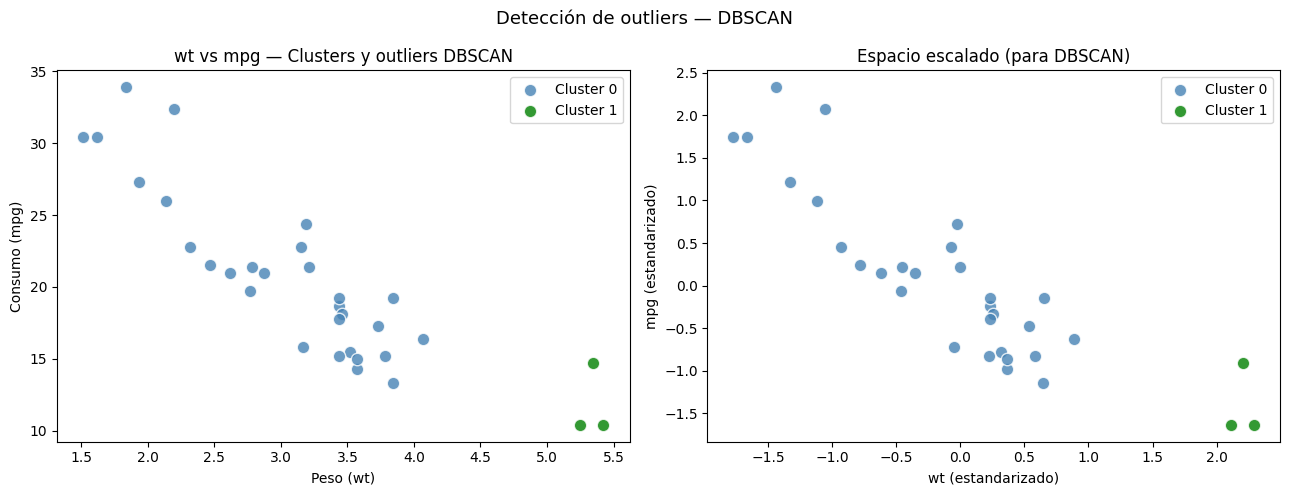

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Detección de outliers — DBSCAN', fontsize=13)

# Espacio original
unique_labels = sorted(set(labels))
palette = {-1: 'black', 0: 'steelblue', 1: 'green', 2: 'orange', 3: 'purple'}
label_names = {-1: 'Outlier (ruido)', 0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2'}

for lbl in unique_labels:
    mask = mtcars_plot['dbscan_label'] == lbl
    subset = mtcars_plot[mask]
    color  = palette.get(lbl, 'gray')
    name   = label_names.get(lbl, f'Cluster {lbl}')
    axes[0].scatter(subset['wt'], subset['mpg'], c=color, label=name,
                    s=80, alpha=0.8, edgecolors='white')

for idx, row in mtcars_plot[mtcars_plot['outlier_dbscan']].iterrows():
    axes[0].annotate(idx, (row['wt'], row['mpg']), fontsize=7,
                     xytext=(3, 3), textcoords='offset points')
axes[0].set_title('wt vs mpg — Clusters y outliers DBSCAN')
axes[0].set_xlabel('Peso (wt)')
axes[0].set_ylabel('Consumo (mpg)')
axes[0].legend()

# Espacio escalado
for lbl in unique_labels:
    mask   = labels == lbl
    color  = palette.get(lbl, 'gray')
    name   = label_names.get(lbl, f'Cluster {lbl}')
    axes[1].scatter(X_scaled[mask, 1], X_scaled[mask, 0], c=color, label=name,
                    s=80, alpha=0.8, edgecolors='white')
axes[1].set_title('Espacio escalado (para DBSCAN)')
axes[1].set_xlabel('wt (estandarizado)')
axes[1].set_ylabel('mpg (estandarizado)')
axes[1].legend()

plt.tight_layout()
plt.show()

Con los parámetros eps=0.8 y min_samples=3, DBSCAN no etiqueta ningún punto como ruido (label = -1), por lo que formalmente no detecta outliers. Sin embargo, sí separa los datos en 2 clusters: el Cluster 0 con la gran mayoría de los autos, y el Cluster 1 con los 2-3 autos de peso muy elevado (wt ≈ 5.2–5.4, mpg ≈ 10–15), que corresponden a los vehículos americanos más grandes. Aunque estos no son etiquetados como ruido, el hecho de que DBSCAN los agrupe aparte indica que son puntos suficientemente alejados del patrón principal como para formar su propio grupo.


#### 3.5 Resumen de outliers detectados por cada método

In [27]:
todos_outliers = set(out_iqr_mpg + out_iqr_wt + out_madn_mpg + out_madn_wt +
                     list(mtcars_plot[mtcars_plot['outlier_maha']].index) +
                     list(mtcars_plot[mtcars_plot['outlier_dbscan']].index))

resumen = pd.DataFrame(index=sorted(todos_outliers))
resumen['IQR (mpg)']       = resumen.index.isin(out_iqr_mpg)
resumen['IQR (wt)']        = resumen.index.isin(out_iqr_wt)
resumen['MADN (mpg)']      = resumen.index.isin(out_madn_mpg)
resumen['MADN (wt)']       = resumen.index.isin(out_madn_wt)
resumen['Mahalanobis']     = resumen.index.isin(mtcars_plot[mtcars_plot['outlier_maha']].index)
resumen['DBSCAN'] = resumen.index.isin(mtcars_plot[mtcars_plot['dbscan_label'] == 1].index)
resumen['# métodos']       = resumen.sum(axis=1).astype(int)

print(resumen.sort_values('# métodos', ascending=False).to_string())

    IQR (mpg)  IQR (wt)  MADN (mpg)  MADN (wt)  Mahalanobis  DBSCAN  # métodos
16      False      True       False      False         True    True          3
14      False      True       False      False        False    True          2
15      False      True       False      False        False    True          2
19       True     False       False      False         True   False          2
17      False     False       False      False         True   False          1


Esta tabla es útil porque nos muestra cuáles autos son señalados por más de un método. Los que aparecen en varios métodos son los candidatos más fuertes a ser outliers reales: no es que un solo criterio los identifique, sino que múltiples enfoques coinciden en que son atípicos.

---
### 4. Impacto de los outliers en las correlaciones

Ahora vamos a ver cómo cambian los coeficientes de correlación cuando excluimos los outliers más robustamente detectados (los que aparecen en al menos 2 métodos).

In [28]:
# Outliers que aparecen en al menos 2 métodos
outliers_consenso = resumen[resumen['# métodos'] >= 2].index.tolist()
print(f"Outliers por consenso (≥2 métodos): {outliers_consenso}")

mtcars_sin_out = mtcars.drop(index=outliers_consenso)
print(f"Tamaño original: {len(mtcars)} | Sin outliers: {len(mtcars_sin_out)}")

Outliers por consenso (≥2 métodos): [14, 15, 16, 19]
Tamaño original: 32 | Sin outliers: 28


In [29]:
# Correlaciones con todos los datos
r_pearson_full,   _ = stats.pearsonr(mtcars['mpg'],  mtcars['wt'])
r_spearman_full,  _ = stats.spearmanr(mtcars['mpg'], mtcars['wt'])
r_kendall_full,   _ = stats.kendalltau(mtcars['mpg'],mtcars['wt'])

# Correlaciones sin outliers
r_pearson_clean,  _ = stats.pearsonr(mtcars_sin_out['mpg'],  mtcars_sin_out['wt'])
r_spearman_clean, _ = stats.spearmanr(mtcars_sin_out['mpg'], mtcars_sin_out['wt'])
r_kendall_clean,  _ = stats.kendalltau(mtcars_sin_out['mpg'],mtcars_sin_out['wt'])

resultados = pd.DataFrame({
    'Método':         ['Pearson', 'Spearman', 'Kendall'],
    'Con outliers':   [r_pearson_full,   r_spearman_full,   r_kendall_full],
    'Sin outliers':   [r_pearson_clean,  r_spearman_clean,  r_kendall_clean],
})
resultados['Diferencia'] = resultados['Sin outliers'] - resultados['Con outliers']
print(resultados.to_string(index=False))

  Método  Con outliers  Sin outliers  Diferencia
 Pearson     -0.867659     -0.870710   -0.003051
Spearman     -0.886422     -0.840345    0.046077
 Kendall     -0.727832     -0.670244    0.057588


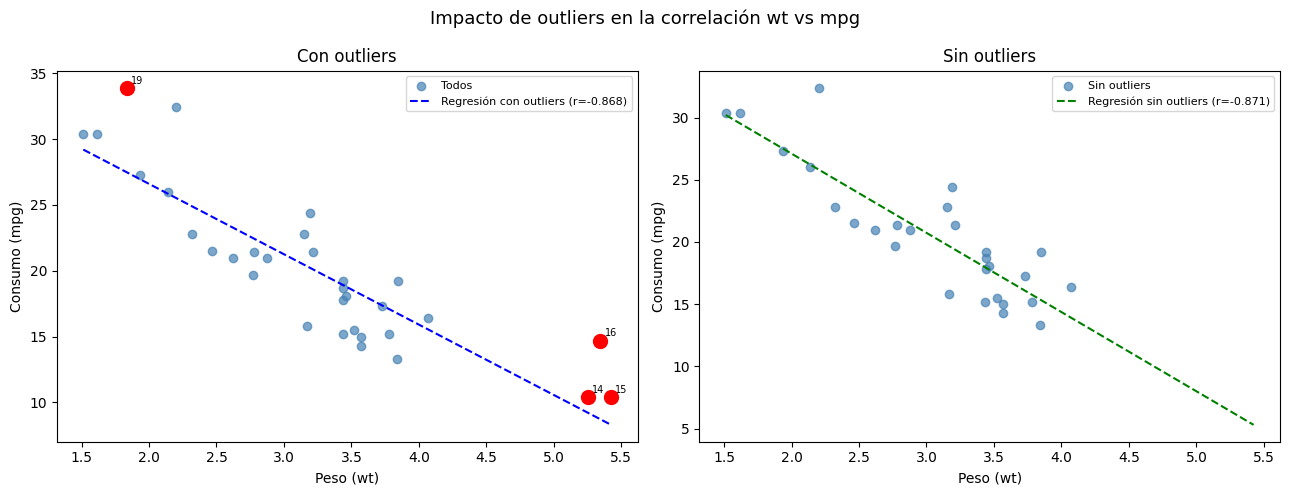

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Impacto de outliers en la correlación wt vs mpg', fontsize=13)

# Scatter con todos los datos
axes[0].scatter(mtcars['wt'], mtcars['mpg'], color='steelblue', alpha=0.7, label='Todos')
for o in outliers_consenso:
    axes[0].scatter(mtcars.loc[o, 'wt'], mtcars.loc[o, 'mpg'],
                    color='red', s=100, zorder=5)
    axes[0].annotate(o, (mtcars.loc[o, 'wt'], mtcars.loc[o, 'mpg']),
                     fontsize=7, xytext=(3, 3), textcoords='offset points')
m, b = np.polyfit(mtcars['wt'], mtcars['mpg'], 1)
x_line = np.linspace(mtcars['wt'].min(), mtcars['wt'].max(), 100)
axes[0].plot(x_line, m*x_line+b, 'b--', linewidth=1.5,
             label=f'Regresión con outliers (r={r_pearson_full:.3f})')
axes[0].set_title('Con outliers')
axes[0].set_xlabel('Peso (wt)')
axes[0].set_ylabel('Consumo (mpg)')
axes[0].legend(fontsize=8)

# Scatter sin outliers
axes[1].scatter(mtcars_sin_out['wt'], mtcars_sin_out['mpg'],
                color='steelblue', alpha=0.7, label='Sin outliers')
m2, b2 = np.polyfit(mtcars_sin_out['wt'], mtcars_sin_out['mpg'], 1)
axes[1].plot(x_line, m2*x_line+b2, 'g--', linewidth=1.5,
             label=f'Regresión sin outliers (r={r_pearson_clean:.3f})')
axes[1].set_title('Sin outliers')
axes[1].set_xlabel('Peso (wt)')
axes[1].set_ylabel('Consumo (mpg)')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

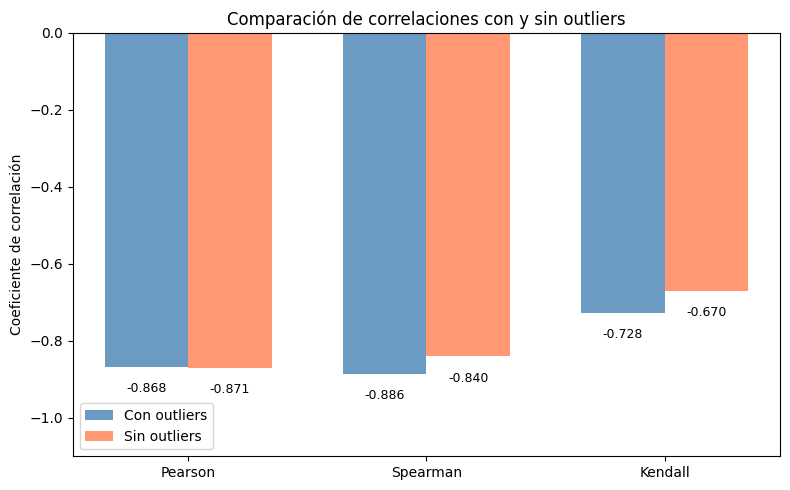

In [31]:
# Gráfico de barras comparando correlaciones
x = np.arange(3)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, resultados['Con outliers'], width,
               label='Con outliers', color='steelblue', alpha=0.8)
bars2 = ax.bar(x + width/2, resultados['Sin outliers'], width,
               label='Sin outliers', color='coral', alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(['Pearson', 'Spearman', 'Kendall'])
ax.set_ylabel('Coeficiente de correlación')
ax.set_title('Comparación de correlaciones con y sin outliers')
ax.set_ylim(-1.1, 0)
ax.legend()
ax.axhline(0, color='black', linewidth=0.5)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() - 0.04,
            f'{bar.get_height():.3f}', ha='center', va='top', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() - 0.04,
            f'{bar.get_height():.3f}', ha='center', va='top', fontsize=9)

plt.tight_layout()
plt.show()

#### Interpretación del impacto

Al quitar los outliers por consenso, los tres coeficientes disminuyen en valor
absoluto, es decir, la correlación negativa se **debilita** al limpiar los datos.

**Pearson** pasa de −0.868 a −0.871: prácticamente no cambia (diferencia de apenas
−0.003), lo que sugiere que estos outliers no distorsionaban significativamente
la relación lineal. Esto es visible en el scatter: los puntos eliminados caen
relativamente cerca de la línea de regresión, por lo que su influencia sobre
Pearson era mínima.

**Spearman** pasa de −0.886 a −0.840 (+0.046 en valor absoluto): este es el cambio
más grande. Al eliminar los puntos con rangos más extremos en `wt` y `mpg`,
la concordancia de orden entre las variables se reduce notablemente. Esto
indica que esos outliers, paradójicamente, reforzaban la correlación de rangos
porque eran los pares más "ordenados" del dataset (el más pesado tenía el menor
mpg, y el más ligero tenía el mayor mpg).

**Kendall** pasa de −0.728 a −0.670 (+0.058): el cambio más pronunciado en
términos relativos. Al retirar los pares más concordantes del ranking, la
proporción de pares discordantes aumenta y el τ se atenúa.

Este comportamiento divergente entre Pearson y los coeficientes de rango es
informativo: Pearson apenas se mueve porque los outliers no eran palancas
de la relación lineal, pero sí eran anclas del ordenamiento, razón por la cual
Spearman y Kendall caen más al eliminarlos.

---
### 5. Reflexión final

### ¿Qué nos dice la relación entre peso y consumo?

La relación negativa entre peso y consumo es robusta y consistente en los tres
coeficientes, tanto con como sin outliers. A mayor peso del vehículo, menor
eficiencia en combustible, lo cual tiene sentido físico directo.

### ¿Por qué importa detectar los outliers?

Los cuatro outliers por consenso corresponden a los autos con `wt` más extremo
(Cadillac Fleetwood, Lincoln Continental, Chrysler Imperial) y al de `mpg` más
alto (Toyota Corolla). Su particularidad es que forman los pares más extremos
y perfectamente ordenados del dataset: el más pesado tiene el menor consumo y
el más liviano tiene el mayor consumo. Por eso, al eliminarlos, Pearson casi
no cambia (no eran palancas de la recta), pero Spearman y Kendall sí se
debilitan porque se pierden los pares más concordantes del ranking.

Esto ilustra una lección importante: un outlier puede simultáneamente ser
"inofensivo" para Pearson y "estructural" para los coeficientes de rango.
Concluir que los outliers "fortalecen o debilitan la correlación" sin
especificar qué coeficiente es una simplificación incorrecta.

En este caso la conclusión cualitativa no cambia (la relación es real y
significativa), pero el análisis detallado del impacto diferenciado por
coeficiente es lo que permite entender realmente qué están midiendo Pearson,
Spearman y Kendall, y cuándo cada uno es más apropiado.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy
import random
from scipy.stats import norm

## Ejercicio 3


### En un proceso de manufactura, dos máquinas, Máquina A y Máquina B, producen piezas metálicas. Se sospecha que ambas tienen distribuciones de rendimiento diferentes, y en ambas pueden ocurrir eventos anómalos que afectan las mediciones.





### 1. Simula dos conjuntos de datos con al menos 40-50 observaciones cada uno, considerando que la Máquina A tenga menor variabilidad y valores más altos, mientras que la Máquina B presente colas más pesadas o mayor dispersión. Introduce manualmente valores atípicos en cada conjunto para representar errores o fallas.

16.0035811651409
19.240145292572883


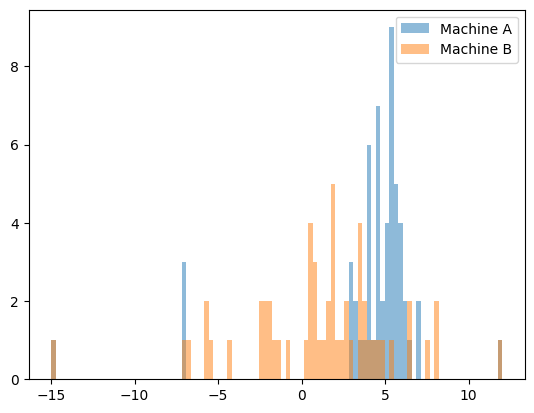

In [ ]:
Machine_A = []
Machine_B = []

np.random.seed(47)


for i in range(50):
    Machine_A.append(np.random.normal(5, 1))
    Machine_B.append(np.random.normal(1, 3))

#hist_A = plt.hist(Machine_A, bins=20, alpha=0.5, label='Machine A')
#hist_B = plt.hist(Machine_B, bins=20, alpha=0.5, label='Machine B')
#plt.legend()

Machine_A_Out = Machine_A.copy()  # or Machine_A[:] or list(Machine_A)
Machine_B_Out = Machine_B.copy()

#print(np.max(Machine_A))
#print(np.min(Machine_A))
#print(np.max(Machine_B))
#print(np.min(Machine_B))



outliers = [10, 8, -9, -15, -7, 4, 12]

for i in range(5):
    Machine_A_Out.append(random.choice(outliers))
    Machine_B_Out.append(random.choice(outliers))

Mean_A = np.mean(Machine_A_Out)
Mean_B = np.mean(Machine_B_Out)

Var_A = np.var(Machine_A_Out)
Var_B = np.var(Machine_B_Out)

Median_A = np.median(Machine_A_Out)
Median_B = np.median(Machine_B_Out)

hist_A = plt.hist(Machine_A_Out, bins=100, alpha=0.5, label='Machine A')
hist_B = plt.hist(Machine_B_Out, bins=100, alpha=0.5, label='Machine B')
plt.legend()

print(Var_A)
print(Var_B)



```
# E`sto tiene formato de código`
```

### 2. Compara la localización de ambas muestras utilizando estimadores tradicionales como la media y robustos como la mediana. Discute la sensibilidad de cada método a valores atípicos. (usa la función de influencia)

In [ ]:
print("MEAN MÁQUINA A")
print("Media Máquina A antes de los atípicos")
print(np.mean(Machine_A))
print("Media Máquina A después de los atípicos")
print(np.mean(Machine_A_Out))
print("")
print("MEDIAN MÁQUINA A")
print("Mediana Máquina A antes de los atípicos")
print(np.median(Machine_A))
print("Mediana Máquina A después de los atípicos")
print(np.median(Machine_A_Out))
print("")
print("COMEDIAN MÁQUINA A")
print("Comedian Máquina A después de los atípicos")
print((Mean_A+Median_A)/2)
print("")
print("MEAN MÁQUINA B")
print("Media Máquina B antes de los atípicos")
print(np.mean(Machine_B))
print("Media Máquina B después de los atípicos")
print(np.mean(Machine_B_Out))
print("")
print("MEDIAN MÁQUINA B")
print("Mediana Máquina B antes de los atípicos")
print(np.median(Machine_B))
print("Mediana Máquina B después de los atípicos")
print(np.median(Machine_B_Out))
print("")
print("COMEDIAN MÁQUINA B")
print("Comedian Máquina B después de los atípicos")
print((Mean_B+Median_B)/2)




MEAN MÁQUINA A
Media Máquina A antes de los atípicos
4.940399695152667
Media Máquina A después de los atípicos
4.054908813775151

MEDIAN MÁQUINA A
Mediana Máquina A antes de los atípicos
5.110441950285788
Mediana Máquina A después de los atípicos
5.047090104597958

COMEDIAN MÁQUINA A
Comedian Máquina A después de los atípicos
4.550999459186555

MEAN MÁQUINA B
Media Máquina B antes de los atípicos
1.1439939060662954
Media Máquina B después de los atípicos
1.0763580964239048

MEDIAN MÁQUINA B
Mediana Máquina B antes de los atípicos
1.6041345492167944
Mediana Máquina B después de los atípicos
1.7029831615896445

COMEDIAN MÁQUINA B
Comedian Máquina B después de los atípicos
1.3896706290067746


Los datos anteriores muestran el impacto de los outliers en ambas distribuciones. La maquina A cambia su media en casi una unidad, alejándose del valor con el cual fueron creados los datos de 5; por su parte, la máquina B tiene una disminución de 0.07, muy inferior a la de la máquina A, este hecho podemos atribuirlo a la mayor varianza de la máquina B. Sus medianas son afectadas muy poco por el efecto de los outliers cambiando en 0.1 en la máquina B y en 0.07 en la máquina A. Por su parte, al comparar el valor del comedian con la media  de cada maquina se evidencia el efecto de los valores atípicos en la simetría original de la distribución.

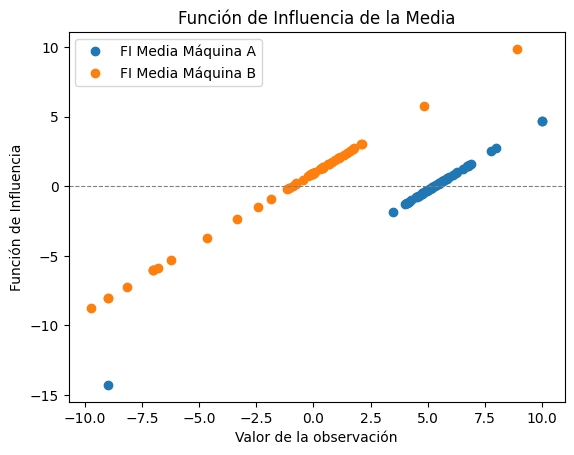

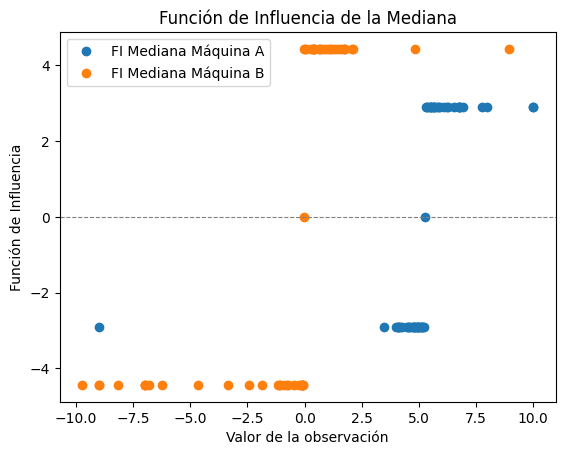

In [ ]:
indices = np.arange(len(Machine_A_Out))

# ── Función de Influencia de la MEDIA ──────────────────────────────────────
FIM_A = [x - Mean_A for x in Machine_A_Out]
FIM_B = [x - Mean_B for x in Machine_B_Out]

plt.figure()
plt.plot(Machine_A_Out, FIM_A, 'o', label='FI Media Máquina A')
plt.plot(Machine_B_Out, FIM_B, 'o', label='FI Media Máquina B')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('Valor de la observación')
plt.ylabel('Función de Influencia')
plt.title('Función de Influencia de la Media')
plt.legend()
plt.show()

# ── Función de Influencia de la MEDIANA ────────────────────────────────────
# Aproximación estándar: sign(x - mediana) / (2 * f(mediana))
# donde f es la densidad estimada en la mediana (usamos densidad normal como aproximación)

def fi_mediana(data, mediana):
    std = np.std(data)
    f_mediana = norm.pdf(mediana, loc=mediana, scale=std)  # ≈ densidad en la mediana
    return [np.sign(x - mediana) / (2 * f_mediana) for x in data]

FIMe_A = fi_mediana(Machine_A_Out, Median_A)
FIMe_B = fi_mediana(Machine_B_Out, Median_B)

plt.figure()
plt.plot(Machine_A_Out, FIMe_A, 'o', label='FI Mediana Máquina A')
plt.plot(Machine_B_Out, FIMe_B, 'o', label='FI Mediana Máquina B')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('Valor de la observación')
plt.ylabel('Función de Influencia')
plt.title('Función de Influencia de la Mediana')
plt.legend()
plt.show()



En los gráficos anteriores se evidencia como no está acotada la función de influencia de la media y como si lo está la de la mediana. Además, por la dispersión de los puntos de la maquina B se ve como los outliers no saltan a la vista de manera tan dramática como con la maquina A.

### 3. Reflexiona sobre la importancia de utilizar métodos robustos en manufactura y control de calidad, considerando escenarios donde se tomen decisiones con base en estimaciones sensibles a valores extremos.

En procesos de manufactura como el analizado, las decisiones operativas y de calidad se toman con base en estimaciones estadísticas de los datos de producción. La elección del estimador adecuado no es trivial: como se evidenció en el análisis de las funciones de influencia, el comportamiento de un estimador ante datos atípicos puede determinar si una conclusión es confiable o completamente errónea.

##### ¿Por qué importa la función de influencia en manufactura?

La función de influencia (FI) de un estimador T mide cuánto cambia T cuando se introduce una observación nueva de valor x en la distribución subyacente. Por su parte, la mediana tiene FI acotada (converge a ±1/(2f(mediana))). Esto tiene consecuencias directas y concretas en el piso de fábrica.

##### Escenario  — Estimación de vida útil de piezas:

Suponga que Máquina A produce piezas cuya resistencia sigue una distribución Normal(5, 1) MPa. Si un sensor falla y registra un valor de 150 MPa (un outlier de origen instrumental), la media muestral puede desplazarse varios puntos, llevando a sobreestimar la resistencia promedio del lote. Con base en esa media inflada, el departamento de ingeniería podría aprobar piezas que en realidad no cumplen especificaciones, generando fallas en campo. La mediana, al tener FI acotada, permanecería casi inalterada ante ese único dato espurio, ofreciendo una estimación más confiable de la tendencia central real.

##### Conclusion

En entornos industriales, los datos raramente son perfectamente limpios. Errores de medición, fallas de sensor, condiciones atípicas de operación y errores humanos generan contaminación que, si se ignora, sesga las estimaciones y conduce a decisiones incorrectas: liberar lotes defectuosos, ajustar innecesariamente parámetros del proceso, o incumplir especificaciones de calidad. Adoptar estimadores con función de influencia acotada y alto punto de quiebre no es un refinamiento académico, sino una necesidad práctica en cualquier sistema serio de control de calidad. La estadística robusta no reemplaza el diagnóstico de los outliers, sino que protege las decisiones mientras ese diagnóstico ocurre.